# Beam-width comparison

Comparison of beam widths $B=1$, $B=3$, and $B=5$ using a fixed VND allocation for each case and budget. All trees use exact $P/Q$ scoring and evaluation.

In [4]:
# Resolve the project whether Jupyter starts here or from the repository root.
from collections import Counter, defaultdict
from hashlib import sha256
import importlib
import json
from pathlib import Path
from statistics import fmean
import sys
from time import perf_counter
from zlib import crc32

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

working = Path.cwd().resolve()
PROJECT = working / "problem-2-min-error-seq" if (working / "problem-2-min-error-seq").is_dir() else working
SOURCE = PROJECT / "src"
if str(SOURCE) not in sys.path:
    sys.path.insert(0, str(SOURCE))

analysis_module = importlib.reload(importlib.import_module("analysis"))
heuristic_module = importlib.reload(importlib.import_module("heuristic"))
from input_data import load_phase_input
from strategy import OutcomeModel, SearchTimeout

select_cases = analysis_module.select_cases
write_csv = analysis_module.write_csv

## Settings

The deterministic test sample contains 180 cases per dimension and covers every $(K,M)$ pair. Checkpointing supports resumed execution.

In [5]:
RUN_MODE = "test"
BEAM_WIDTHS = (1, 3, 5)
MAX_ITERATIONS = 30
MOVE_SIZES = (1, 2, 3)
TIME_LIMIT_SECONDS = 30.0
RESUME = True
STUDY_VERSION = 1

BEAM_STYLES = {
    1: ("#1f77b4", "o", "-"),
    3: ("#d62728", "s", "--"),
    5: ("#2ca02c", "^", "-."),
}
OUTPUT = PROJECT / "results" / "beam_width" / RUN_MODE
CHECKPOINT = OUTPUT / "records.jsonl"

print("Run mode:", RUN_MODE)
print("Beam widths:", BEAM_WIDTHS)
print("Output:", OUTPUT)

Run mode: test
Beam widths: (1, 3, 5)
Output: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/problem-2-min-error-seq/results/beam_width/test


## Beam-search evaluation

The VND allocation is computed once per case and budget, then reused for all beam widths.

In [6]:
def vnd_allocation(model, *, random_seed):
    allocation = heuristic_module._initial_allocation(
        model.M, model.N, "near_uniform", random_seed
    )
    _, pair_errors = heuristic_module._compute_pair_errors(
        model.pairs, model.M, allocation, model.phases
    )
    score = heuristic_module._allocation_score(pair_errors)
    level = 0
    iterations = 0

    while level < len(MOVE_SIZES):
        model.check_time()
        if iterations >= MAX_ITERATIONS:
            break
        iterations += 1
        candidate = heuristic_module._best_allocation_neighbor(
            allocation,
            model.pairs,
            model.M,
            model.phases,
            score,
            MOVE_SIZES[level],
            0.0,
        )
        if candidate is None:
            level += 1
        else:
            allocation, score = candidate
            level = 0
    model.check_time()
    return allocation, iterations


def evaluate_beam_tree(K, M, N, phases, allocation, beam_width):
    model = OutcomeModel(K, M, N, phases, time_limit=TIME_LIMIT_SECONDS)
    pair_locations, pair_errors = heuristic_module._compute_pair_errors(
        model.pairs, model.M, allocation, model.phases
    )
    pair_outcomes = {
        pair: model.probabilities(
            pair,
            pair_locations[pair],
            allocation[pair_locations[pair]],
        )
        for pair in model.pairs
    }
    tree = heuristic_module._build_tree_with_beam_search(
        K,
        pair_locations,
        pair_errors,
        pair_outcomes,
        beam_width,
        check_time=model.check_time,
    )
    return model.result(allocation, tree)


def timed_result(function):
    started = perf_counter()
    try:
        result = function()
        return "ok", result, perf_counter() - started
    except SearchTimeout:
        return "timeout", None, perf_counter() - started


def load_checkpoint(path):
    records = {}
    if not path.exists():
        return records
    for line in path.read_text().splitlines():
        try:
            record = json.loads(line)
            records[record["fingerprint"]] = record
        except (ValueError, KeyError):
            continue
    return records


def calculate_record(dataset, path, metadata, budget_level, budget, settings_hash):
    K, M, phases = load_phase_input(path)
    seed = crc32(f"{dataset}:{path.stem}:{budget}".encode())
    fingerprint = sha256(
        path.read_bytes()
        + settings_hash.encode()
        + json.dumps(metadata, sort_keys=True).encode()
        + str(budget).encode()
    ).hexdigest()

    allocation_model = OutcomeModel(
        K, M, budget, phases, time_limit=TIME_LIMIT_SECONDS
    )
    allocation_status, allocation_result, allocation_seconds = timed_result(
        lambda: vnd_allocation(allocation_model, random_seed=seed)
    )
    if allocation_status == "ok":
        allocation, iterations = allocation_result
    else:
        allocation, iterations = None, None

    record = {
        "fingerprint": fingerprint,
        "dataset": dataset,
        "case": path.stem,
        "dimension": int(metadata["spatial_dimension"]),
        "field_family": metadata["field_model"],
        "replicate": int(metadata["replicate"]),
        "K": K,
        "M": M,
        "N": budget,
        "budget_level": budget_level,
        "budget_fraction": budget / int(metadata["minimum_sensors_for_zero_error"]),
        "allocation": None if allocation is None else list(allocation),
        "vnd_iterations": iterations,
        "allocation_status": allocation_status,
        "allocation_seconds": allocation_seconds,
    }

    for beam_width in BEAM_WIDTHS:
        if allocation is None:
            status, result, seconds = "timeout", None, allocation_seconds
        else:
            status, result, seconds = timed_result(
                lambda width=beam_width: evaluate_beam_tree(
                    K, M, budget, phases, allocation, width
                )
            )
        record[f"beam_{beam_width}_status"] = status
        record[f"beam_{beam_width}_error"] = (
            None if result is None else result.actual_error
        )
        record[f"beam_{beam_width}_seconds"] = seconds
    return fingerprint, record


def run_beam_study():
    entries = select_cases(PROJECT, "extended", RUN_MODE, exact_k_max=4)
    settings = {
        "study_version": STUDY_VERSION,
        "run_mode": RUN_MODE,
        "beam_widths": BEAM_WIDTHS,
        "max_iterations": MAX_ITERATIONS,
        "move_sizes": MOVE_SIZES,
        "time_limit_seconds": TIME_LIMIT_SECONDS,
    }
    code_hash = sha256(
        b"".join(p.read_bytes() for p in sorted(SOURCE.glob("*.py")))
    ).hexdigest()
    settings_hash = sha256(
        (json.dumps(settings, sort_keys=True) + code_hash).encode()
    ).hexdigest()
    cached = load_checkpoint(CHECKPOINT) if RESUME else {}
    OUTPUT.mkdir(parents=True, exist_ok=True)
    totals = Counter(dataset for dataset, _, _ in entries)
    completed = Counter()
    selected_records = []

    for dataset, path, metadata in entries:
        for budget_level, budget in enumerate(metadata["sensor_budgets"], 1):
            budget = int(budget)
            fingerprint = sha256(
                path.read_bytes()
                + settings_hash.encode()
                + json.dumps(metadata, sort_keys=True).encode()
                + str(budget).encode()
            ).hexdigest()
            if fingerprint in cached:
                record = cached[fingerprint]
            else:
                fingerprint, record = calculate_record(
                    dataset,
                    path,
                    metadata,
                    budget_level,
                    budget,
                    settings_hash,
                )
                with CHECKPOINT.open("a") as stream:
                    stream.write(json.dumps(record, allow_nan=False) + "\n")
                    stream.flush()
                cached[fingerprint] = record
            selected_records.append(record)

        completed[dataset] += 1
        print(
            f"{dataset}: completed case {completed[dataset]}/{totals[dataset]} "
            f"({metadata['field_model']}, K={metadata['K']}, M={metadata['M']})",
            flush=True,
        )
    return selected_records


records = run_beam_study()
print("Selected case-budget records:", len(records))

benchmark_1d: completed case 1/180 (gaussian, K=3, M=2)
benchmark_1d: completed case 2/180 (quadratic, K=3, M=2)
benchmark_1d: completed case 3/180 (sinusoidal, K=3, M=2)
benchmark_1d: completed case 4/180 (quadratic, K=3, M=3)
benchmark_1d: completed case 5/180 (sinusoidal, K=3, M=3)
benchmark_1d: completed case 6/180 (gaussian, K=3, M=3)
benchmark_1d: completed case 7/180 (sinusoidal, K=3, M=4)
benchmark_1d: completed case 8/180 (gaussian, K=3, M=4)
benchmark_1d: completed case 9/180 (quadratic, K=3, M=4)
benchmark_1d: completed case 10/180 (gaussian, K=3, M=5)
benchmark_1d: completed case 11/180 (quadratic, K=3, M=5)
benchmark_1d: completed case 12/180 (sinusoidal, K=3, M=5)
benchmark_1d: completed case 13/180 (quadratic, K=3, M=6)
benchmark_1d: completed case 14/180 (sinusoidal, K=3, M=6)
benchmark_1d: completed case 15/180 (gaussian, K=3, M=6)
benchmark_1d: completed case 16/180 (sinusoidal, K=3, M=7)
benchmark_1d: completed case 17/180 (gaussian, K=3, M=7)
benchmark_1d: completed

## Summary tables

Matched error and runtime results for all beam widths.

In [7]:
def matched_records(records):
    return [
        record for record in records
        if all(record[f"beam_{width}_status"] == "ok" for width in BEAM_WIDTHS)
    ]


def summary_rows(records, *, by_budget):
    groups = defaultdict(list)
    for record in matched_records(records):
        key = (
            int(record["dimension"]),
            int(record["budget_level"]) if by_budget else None,
            None,
        )
        groups[key].append(record)

    rows = []
    for (dimension, level, _), selected in sorted(groups.items()):
        for width in BEAM_WIDTHS:
            row = {
                "dimension": dimension,
                "beam_width": width,
                "runs": len(selected),
                "mean_error_probability": fmean(
                    float(record[f"beam_{width}_error"]) for record in selected
                ),
                "mean_tree_seconds": fmean(
                    float(record[f"beam_{width}_seconds"]) for record in selected
                ),
            }
            if by_budget:
                row["budget_level"] = level
                row["mean_budget_fraction"] = fmean(
                    float(record["budget_fraction"]) for record in selected
                )
            rows.append(row)
    return rows


def markdown_table(rows):
    columns = list(rows[0])
    lines = [
        "| " + " | ".join(column.replace("_", " ").title() for column in columns) + " |",
        "|" + "|".join("---:" for _ in columns) + "|",
    ]
    for row in rows:
        values = []
        for column in columns:
            value = row[column]
            values.append(f"{value:.5f}" if isinstance(value, float) else str(value))
        lines.append("| " + " | ".join(values) + " |")
    return "\n".join(lines)


overall_rows = summary_rows(records, by_budget=False)
budget_rows = summary_rows(records, by_budget=True)
case_rows = [
    {key: value for key, value in record.items() if key != "fingerprint"}
    for record in records
]
timeout_rows = [
    {
        "dataset": record["dataset"],
        "case": record["case"],
        "dimension": record["dimension"],
        "K": record["K"],
        "M": record["M"],
        "N": record["N"],
        "beam_width": width,
        "seconds": record[f"beam_{width}_seconds"],
    }
    for record in records
    for width in BEAM_WIDTHS
    if record[f"beam_{width}_status"] != "ok"
]

write_csv(OUTPUT / "tables" / "case_results.csv", case_rows)
write_csv(OUTPUT / "tables" / "overall_summary.csv", overall_rows)
write_csv(OUTPUT / "tables" / "budget_summary.csv", budget_rows)
write_csv(
    OUTPUT / "tables" / "timeouts.csv",
    timeout_rows,
    fieldnames=("dataset", "case", "dimension", "K", "M", "N", "beam_width", "seconds"),
)

display(Markdown("### Overall beam-width summary"))
display(Markdown(markdown_table(overall_rows)))
display(Markdown("### Beam-width summary by budget"))
display(Markdown(markdown_table(budget_rows)))
print("Matched records:", len(matched_records(records)), "of", len(records))
print("Timeouts:", len(timeout_rows))

### Overall beam-width summary

| Dimension | Beam Width | Runs | Mean Error Probability | Mean Tree Seconds |
|---:|---:|---:|---:|---:|
| 1 | 1 | 716 | 0.11287 | 0.19939 |
| 1 | 3 | 716 | 0.11133 | 0.61712 |
| 1 | 5 | 716 | 0.11086 | 1.02920 |
| 2 | 1 | 717 | 0.13677 | 0.19430 |
| 2 | 3 | 717 | 0.13523 | 0.60331 |
| 2 | 5 | 717 | 0.13484 | 1.02306 |

### Beam-width summary by budget

| Dimension | Beam Width | Runs | Mean Error Probability | Mean Tree Seconds | Budget Level | Mean Budget Fraction |
|---:|---:|---:|---:|---:|---:|---:|
| 1 | 1 | 180 | 0.27445 | 0.19734 | 1 | 0.23575 |
| 1 | 3 | 180 | 0.27222 | 0.60224 | 1 | 0.23575 |
| 1 | 5 | 180 | 0.27149 | 1.01261 | 1 | 0.23575 |
| 1 | 1 | 180 | 0.11326 | 0.19958 | 2 | 0.44719 |
| 1 | 3 | 180 | 0.11118 | 0.61815 | 2 | 0.44719 |
| 1 | 5 | 180 | 0.11049 | 1.02496 | 2 | 0.44719 |
| 1 | 1 | 178 | 0.04264 | 0.19964 | 3 | 0.66788 |
| 1 | 3 | 178 | 0.04121 | 0.63077 | 3 | 0.66788 |
| 1 | 5 | 178 | 0.04086 | 1.04062 | 3 | 0.66788 |
| 1 | 1 | 178 | 0.01933 | 0.20103 | 4 | 0.86413 |
| 1 | 3 | 178 | 0.01889 | 0.61751 | 4 | 0.86413 |
| 1 | 5 | 178 | 0.01878 | 1.03884 | 4 | 0.86413 |
| 2 | 1 | 180 | 0.29989 | 0.19193 | 1 | 0.22165 |
| 2 | 3 | 180 | 0.29735 | 0.59122 | 1 | 0.22165 |
| 2 | 5 | 180 | 0.29672 | 1.00231 | 1 | 0.22165 |
| 2 | 1 | 180 | 0.14300 | 0.19309 | 2 | 0.41124 |
| 2 | 3 | 180 | 0.14089 | 0.60132 | 2 | 0.41124 |
| 2 | 5 | 180 | 0.14035 | 1.01749 | 2 | 0.41124 |
| 2 | 1 | 179 | 0.06526 | 0.19535 | 3 | 0.61460 |
| 2 | 3 | 179 | 0.06423 | 0.60754 | 3 | 0.61460 |
| 2 | 5 | 179 | 0.06396 | 1.03566 | 3 | 0.61460 |
| 2 | 1 | 178 | 0.03743 | 0.19688 | 4 | 0.79082 |
| 2 | 3 | 178 | 0.03697 | 0.61331 | 4 | 0.79082 |
| 2 | 5 | 178 | 0.03685 | 1.03698 | 4 | 0.79082 |

Matched records: 1433 of 1433
Timeouts: 0


## Accuracy and runtime

Error reduction relative to $B=1$ and mean tree runtime by $K$.

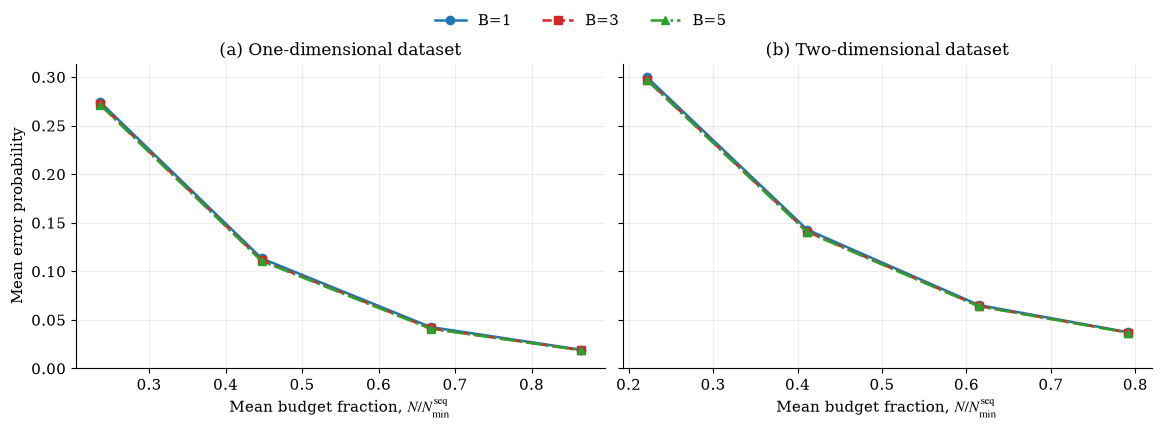

Saved beam-width outputs under: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/problem-2-min-error-seq/results/beam_width/test


In [8]:
def beam_effect_rows(records):
    groups = defaultdict(list)
    for record in matched_records(records):
        groups[(int(record["dimension"]), int(record["K"]))].append(record)

    rows = []
    for (dimension, K), selected in sorted(groups.items()):
        baseline = [float(record["beam_1_error"]) for record in selected]
        for width in BEAM_WIDTHS:
            errors = [
                float(record[f"beam_{width}_error"]) for record in selected
            ]
            reductions = [
                base_error - error
                for base_error, error in zip(baseline, errors)
            ]
            rows.append({
                "dimension": dimension,
                "K": K,
                "beam_width": width,
                "runs": len(selected),
                "mean_error_probability": fmean(errors),
                "mean_error_reduction_vs_b1": fmean(reductions),
                "improved_vs_b1_percent": (
                    100.0 * sum(value > 1e-12 for value in reductions)
                    / len(reductions)
                ),
                "mean_tree_seconds": fmean(
                    float(record[f"beam_{width}_seconds"])
                    for record in selected
                ),
            })
    return rows


def plot_beam_widths(rows):
    plt.rcParams.update({
        "font.family": "serif",
        "font.size": 11,
        "mathtext.fontset": "stix",
        "pdf.fonttype": 42,
        "axes.spines.top": False,
        "axes.spines.right": False,
    })
    figure, axes = plt.subplots(
        2,
        2,
        figsize=(11.5, 7.2),
        sharex="col",
        layout="constrained",
    )
    titles = {
        (0, 1): "(a) Error reduction, one-dimensional dataset",
        (0, 2): "(b) Error reduction, two-dimensional dataset",
        (1, 1): "(c) Runtime, one-dimensional dataset",
        (1, 2): "(d) Runtime, two-dimensional dataset",
    }

    for column, dimension in enumerate((1, 2)):
        panel = [row for row in rows if int(row["dimension"]) == dimension]
        for width in BEAM_WIDTHS:
            selected = [
                row for row in panel if int(row["beam_width"]) == width
            ]
            color, marker, line = BEAM_STYLES[width]
            K_values = [int(row["K"]) for row in selected]
            axes[0, column].plot(
                K_values,
                [1000.0 * row["mean_error_reduction_vs_b1"] for row in selected],
                color=color,
                marker=marker,
                linestyle=line,
                linewidth=1.8,
                label=f"B={width}",
            )
            axes[1, column].plot(
                K_values,
                [row["mean_tree_seconds"] for row in selected],
                color=color,
                marker=marker,
                linestyle=line,
                linewidth=1.8,
                label=f"B={width}",
            )

        axes[0, column].axhline(0.0, color="0.55", linewidth=0.9)
        axes[1, column].set_yscale("log")
        axes[1, column].set_xlabel(r"Number of candidate fields, $K$")
        for row_index in (0, 1):
            axes[row_index, column].set_title(
                titles[(row_index, dimension)], fontsize=12
            )
            axes[row_index, column].grid(alpha=0.22)

    axes[0, 0].set_ylabel(r"Mean error reduction vs. $B=1$ ($\times 10^{-3}$)")
    axes[1, 0].set_ylabel("Mean tree runtime (s), logarithmic scale")
    handles, labels = axes[0, 0].get_legend_handles_labels()
    figure.legend(
        handles,
        labels,
        loc="outside upper center",
        ncol=3,
        frameon=False,
    )
    return figure


effect_rows = beam_effect_rows(records)
write_csv(OUTPUT / "tables" / "effect_by_k.csv", effect_rows)
figure = plot_beam_widths(effect_rows)
figure_directory = OUTPUT / "figures"
figure_directory.mkdir(parents=True, exist_ok=True)
for extension in ("pdf", "png"):
    figure.savefig(
        figure_directory / f"beam_width_comparison.{extension}",
        dpi=300,
        bbox_inches="tight",
    )
display(figure)
plt.close(figure)
print("Saved beam-width outputs under:", OUTPUT)

## Saved outputs

Resumable records, tables, and figures are stored in `results/beam_width/test`.